In [1]:
# !uv pip install --system scikit-learn==1.5.2

try:
    from autogluon.tabular import TabularPredictor
except:
    !uv pip install autogluon
    from autogluon.tabular import TabularPredictor

## -- To use Foundation models: data ~100k rows --
!uv pip install autogluon.tabular[tabarena]

Using Python 3.12.13 environment at: /usr
Resolved 231 packages in 5.53s
⠙ Preparing packages... (0/52)
⠙ Preparing packages... (0/52)
⠙ Preparing packages... (0/52)
⠙ Preparing packages... (0/52)
opentelemetry-exporter-prometheus ------------------------------     0 B/12.91 KiB
⠙ Preparing packages... (0/52)
opentelemetry-exporter-prometheus ------------------------------ 12.91 KiB/12.91 KiB
⠙ Preparing packages... (0/52)
opentelemetry-exporter-prometheus ------------------------------ 12.91 KiB/12.91 KiB
⠙ Preparing packages... (0/52)
opentelemetry-exporter-prometheus ------------------------------ 12.91 KiB/12.91 KiB
⠙ Preparing packages... (0/52)
ordered-set                       ------------------------------     0 B/7.46 KiB
opentelemetry-exporter-prometheus ------------------------------ 12.91 KiB/12.91 KiB
⠙ Preparing packages... (0/52)
ordered-set                       ------------------------------ 7.46 KiB/7.46 KiB
opentelemetry-exporter-prometheus --------------------------

In [2]:
# %%capture saved_prints
!uv pip install ipywidgets
!apt-get install -qq -y graphviz graphviz-dev && pip install -q pydot
!pip install -qq pygraphviz

Using Python 3.12.13 environment at: /usr
Checked 1 package in 195ms
Selecting previously unselected package libatk1.0-data.
(Reading database ... 120968 files and directories currently installed.)
Preparing to unpack .../00-libatk1.0-data_2.36.0-3build1_all.deb ...
Unpacking libatk1.0-data (2.36.0-3build1) ...
Selecting previously unselected package libatk1.0-0:amd64.
Preparing to unpack .../01-libatk1.0-0_2.36.0-3build1_amd64.deb ...
Unpacking libatk1.0-0:amd64 (2.36.0-3build1) ...
Selecting previously unselected package libgtk2.0-common.
Preparing to unpack .../02-libgtk2.0-common_2.24.33-2ubuntu2.1_all.deb ...
Unpacking libgtk2.0-common (2.24.33-2ubuntu2.1) ...
Selecting previously unselected package libxcomposite1:amd64.
Preparing to unpack .../03-libxcomposite1_1%3a0.4.5-1build2_amd64.deb ...
Unpacking libxcomposite1:amd64 (1:0.4.5-1build2) ...
Selecting previously unselected package libgtk2.0-0:amd64.
Preparing to unpack .../04-libgtk2.0-0_2.24.33-2ubuntu2.1_amd64.deb ...
Unpack

In [3]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [4]:
import random
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Image

from tqdm.auto import tqdm
from time import time, sleep
import itertools

try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

import warnings

## -- Global Settings --
# sklearn.set_config(transform_output="pandas")
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# plt.style.use("ggplot")

In [5]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 13,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [6]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"data.csv")

# if torch.cuda.is_available():
#     submit = cudf.DataFrame(submit)
#     train = cudf.DataFrame(train)
#     test = cudf.DataFrame(test)
#     orig = cudf.DataFrame(orig)

## =================================================================================

TARGET, ID = 'satisfaction', 'id'

train[TARGET] = train[TARGET].map({True: 1, False: 0})
orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET, ID]]
num_cols  = [c for c in train.columns if c not in cat_cols+[TARGET, ID]]
base_cols = [c for c in train.columns if c not in [TARGET, ID]]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

print(f"Frame type: {type(train)}\n")

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total base features: {len(base_cols)}")

Frame type: <class 'pandas.core.frame.DataFrame'>

Train shape: (699635, 22)
Test shape: (299844, 21)
Orig shape: (129880, 22)
Total Numerical: 17
Total Categorical: 4
Total base features: 21


In [7]:
train.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


In [8]:
MODELS_PATH = "/kaggle/working/ag_Flight_models/"
# !rm -r {MODELS_PATH}

In [9]:
## -- RUN 1: Use train data -- 

predictor = TabularPredictor(
                label = TARGET,
         problem_type = "binary",
          eval_metric = 'roc_auc',
                 path = MODELS_PATH,
    ).fit(
                   train_data = orig, # <- original data
                      presets = "best_quality_v150", # v1_original_best_quality_v150
                num_bag_folds = 4,
             dynamic_stacking = False,
             num_stack_levels = 0, # 0 if False
                   time_limit = 3600*2,
                   auto_stack = False,
                 # num_bag_sets = 2,
                  # ag_args_fit = {'num_cpus': os.cpu_count()},
)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.12.13
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Sun Sep 27 17:32:16 UTC 2026
CPU Count:          4
Pytorch Version:    2.10.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       29.71 GB / 31.35 GB (94.8%)
Disk Space Avail:   19.50 GB / 19.52 GB (99.9%)
Presets specified: ['best_quality_v150']
Using hyperparameters preset: hyperparameters='zeroshot_2025_12_18_cpu'
Beginning AutoGluon training ... Time limit = 7200s
AutoGluon will save models to "/kaggle/working/ag_Flight_models"
Train Data Rows:    129880
Train Data Columns: 21
Label Column:       satisfaction
Problem Type:       binary
Preprocessing data...
Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    30429.5

In [10]:
## -- Get Summary -- 
print(f"-> Total models : {len(predictor.model_names())}")
print(f"-> Best model   : {predictor.model_best}\n") 

leaderboard = predictor.leaderboard(silent=True)
leaderboard.style.background_gradient(subset=['score_val'], cmap='Spectral')

-> Total models : 9
-> Best model   : WeightedEnsemble_L2



,model,score_val,eval_metric,pred_time_val,fit_time,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,0.995298,roc_auc,142.784470,5993.721652,0.021827,5.044754,2,True,9
1,LightGBM_r163_BAG_L1,0.995191,roc_auc,118.128913,107.432879,118.128913,107.432879,1,True,5
2,CatBoost_c1_BAG_L1,0.994964,roc_auc,0.508739,578.866061,0.508739,578.866061,1,True,1
3,LightGBMPrep_r13_BAG_L1,0.994810,roc_auc,21.000241,2025.654563,21.000241,2025.654563,1,True,2
4,NeuralNetTorch_r37_BAG_L1,0.994425,roc_auc,1.609371,3086.424105,1.609371,3086.424105,1,True,4
5,NeuralNetFastAI_r25_BAG_L1,0.994236,roc_auc,1.515378,190.299290,1.515378,190.299290,1,True,6
6,LightGBM_r177_BAG_L1,0.989162,roc_auc,530.079240,281.958130,530.079240,281.958130,1,True,3
7,LightGBM_r72_BAG_L1,0.987654,roc_auc,171.484117,92.777506,171.484117,92.777506,1,True,8
8,LightGBMPrep_r41_BAG_L1,0.984932,roc_auc,9.812219,583.528032,9.812219,583.528032,1,True,7


In [11]:
# ## -- RUN 2: Use original data as extra learning input --
# predictor.fit_pseudolabel(
#                 orig,
#                 use_ensemble = True,
#                 fit_ensemble = True,
#                 time_limit   = 3600*2,
# )

In [12]:
# ## -- Get Summary -- 
# print(f"-> Total models : {len(predictor.model_names())}")
# print(f"-> Best model   : {predictor.model_best}\n") 

# ## -- RUN 2 RESULTS -- 
# leaderboard = predictor.leaderboard(silent=True)
# leaderboard.style.background_gradient(subset=["score_val"], cmap="Spectral")

In [13]:
## -- Create folder directory to save predictions --
SAVE_PATH = "/kaggle/working/AG_preds/"
# FILE_NAME = f"ag_{TARGET}_orig.parquet"

!mkdir {SAVE_PATH}

print(f"File path created: {SAVE_PATH}")

File path created: /kaggle/working/AG_preds/


In [14]:
def make_best_predictions(predictor, df=None, save_path=SAVE_PATH, data_type=None, use_distill=False):
    df_1 = df.copy()

    if TARGET in df_1.columns: df_1 = df_1.drop(columns=[TARGET])

    if use_distill:
        print("Exporting distilled model predictions", end="... ")
        distilled_model_names = predictor.distill()
        # ldr = predictor.leaderboard()
        model_to_deploy = distilled_model_names[0]
        preds = predictor.predict_proba(df_1, model=model_to_deploy, as_pandas=False, as_multiclass=False)
        fila_name = f"{save_path}ag_distill_{TARGET}_{data_type}.npy"
        np.save(fila_name, preds)
    else:
        print("Exporting best model predictions", end="... ")
        preds = predictor.predict_proba(df_1, as_pandas=False, as_multiclass=False)
        fila_name = f"{save_path}ag_best_{TARGET}_{data_type}.npy"
        np.save(fila_name, preds)

    print(f"✓ Finished ({len(preds)}) samples")
    print(fila_name)

    return preds

print('Prediction function ready!')

Prediction function ready!


In [15]:
%%time

final_oof = make_best_predictions(
    predictor,
    df=orig,
    save_path=SAVE_PATH,
    data_type="orig",
    # use_distill=True,
)

print()
final_oof

Exporting best model predictions... ✓ Finished (129880) samples
/kaggle/working/AG_preds/ag_best_satisfaction_orig.npy

CPU times: user 7min 59s, sys: 4.4 s, total: 8min 4s
Wall time: 4min 9s


array([5.5652657e-05, 5.3615624e-04, 9.9983561e-01, ..., 8.4277206e-05,
       9.9851573e-01, 1.6101966e-04], shape=(129880,), dtype=float32)

In [16]:
%%time

final_train = make_best_predictions(
    predictor,
    df=train,
    save_path=SAVE_PATH,
    data_type="trn",
    # use_distill=True,
)

print()
final_train

Exporting best model predictions... ✓ Finished (699635) samples
/kaggle/working/AG_preds/ag_best_satisfaction_trn.npy

CPU times: user 40min 7s, sys: 47.2 s, total: 40min 54s
Wall time: 21min 5s


array([2.6396990e-01, 9.9907947e-01, 2.0969211e-04, ..., 9.9991971e-01,
       9.9915814e-01, 1.6482288e-04], shape=(699635,), dtype=float32)

In [17]:
%%time

final_test = make_best_predictions(
    predictor,
    df=test,
    save_path=SAVE_PATH,
    data_type="tst",
    # use_distill=True,
)

print()
final_test

Exporting best model predictions... ✓ Finished (299844) samples
/kaggle/working/AG_preds/ag_best_satisfaction_tst.npy

CPU times: user 16min 56s, sys: 15.7 s, total: 17min 12s
Wall time: 8min 50s


array([2.7767757e-01, 7.6630098e-01, 9.6234578e-01, ..., 2.9958418e-01,
       2.5392315e-04, 1.0308229e-04], shape=(299844,), dtype=float32)

In [18]:
# ## -- Make submission --
# final_preds = predictor.predict_proba(pred_df, as_multiclass=False)
# final_score = np.round(leaderboard.score_val.max(), 5)

# n = f"submit_autogluon_{str(final_score).split('.')[1]}.csv"
# submit[TARGET] = final_preds
# submit.to_csv(n, index=False)

# print('Submission file exported -> ', n)
# submit.head()

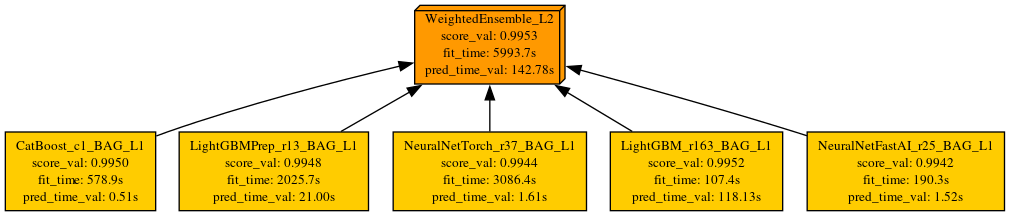

In [19]:
predictor.plot_ensemble_model(filename='ensemble_model.png')
display(Image(f'{MODELS_PATH}ensemble_model.png'))

In [20]:
## -- Extract model scores --
result_df = leaderboard[['model', 'score_val']]

max_score = result_df['score_val'].max()
min_score = result_df['score_val'].min()

result_df

,model,score_val
0,WeightedEnsemble_L2,0.995298
1,LightGBM_r163_BAG_L1,0.995191
2,CatBoost_c1_BAG_L1,0.994964
3,LightGBMPrep_r13_BAG_L1,0.994810
4,NeuralNetTorch_r37_BAG_L1,0.994425
5,NeuralNetFastAI_r25_BAG_L1,0.994236
6,LightGBM_r177_BAG_L1,0.989162
7,LightGBM_r72_BAG_L1,0.987654
8,LightGBMPrep_r41_BAG_L1,0.984932


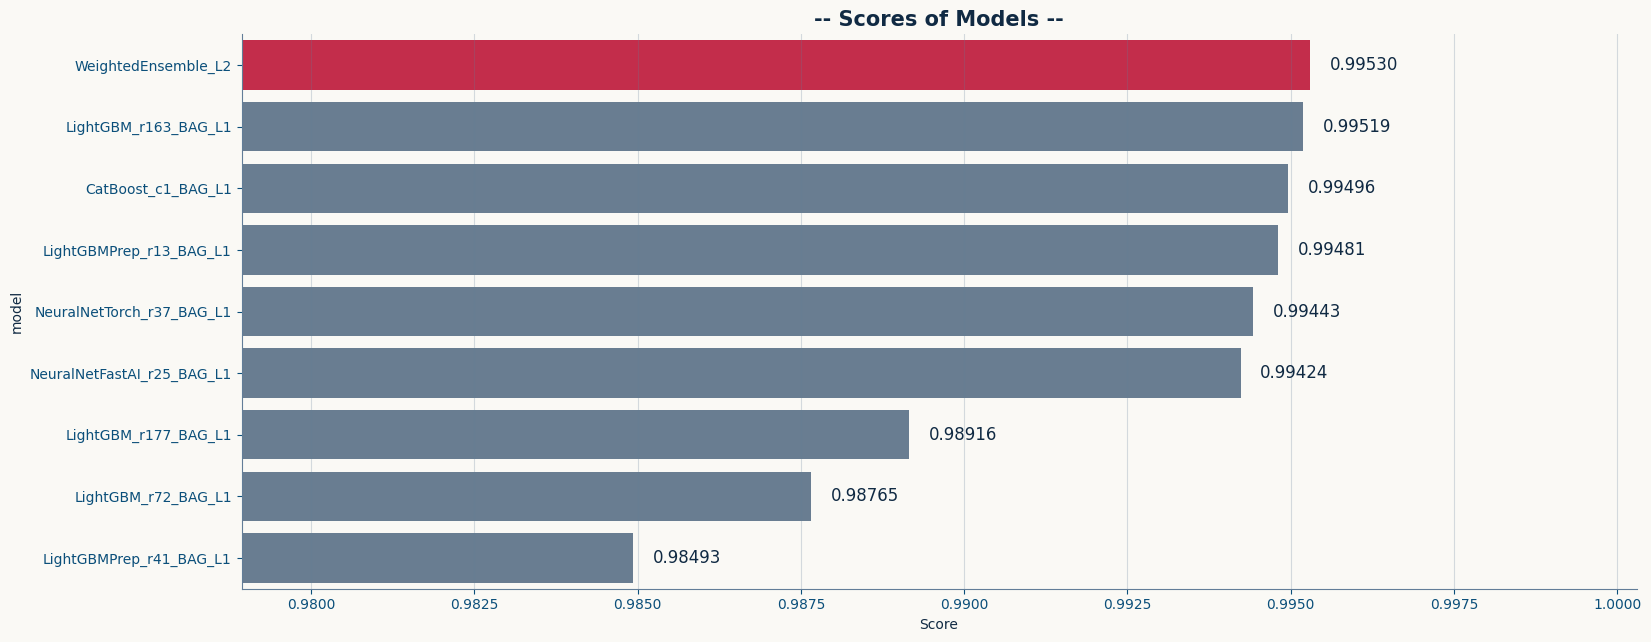

In [21]:
## -- Plot model scores --
plt.figure(figsize=(18, len(result_df)*0.8))
# plt.stem(
#     result_df.index,
#     result_df[0],
#     orientation = 'horizontal',
#     bottom = min_score - 0.0055,
#     markerfmt = 'C3o'
# )

sns.barplot(
    result_df, x=result_df['score_val'], y=result_df['model'], #width=0.5,
    palette=[MUTED if c < max_score else CRIM for c in result_df['score_val']]
)
plt.xlim(min_score - 0.006, max_score + 0.005)
plt.xlabel('Score')
plt.title('-- Scores of Models --', fontsize=15)

for i, value in enumerate(result_df['score_val']):
    plt.text(value+3e-4, i, f'{abs(value):.5f}', ha='left', va='center', fontdict={'size': 12})

plt.grid(True, axis='x')
# plt.tight_layout()
plt.show()

In [22]:
# predictor.model_names()

In [23]:
# ## -- Permutation Feature Importances --
# feat_imp = predictor.feature_importance(
#                         data = X_test,
#                         # time_limit = 3600,
#                         # model = 'LightGBM_BAG_L1',
#                         # features = None,
#                         # feature_stage = 'transformed',
#                         # subsample_size = 5000,
#                         # num_shuffle_sets = 10,
#                         # include_confidence_band = True,
#                         confidence_level = 0.95,
#                         # silent = False
# ) 

# feat_imp.style.background_gradient(subset=["importance"], cmap="Spectral")

# plt.figure(figsize=(18, 35))
# sns.barplot(data=feat_imp, y=feat_imp.index, x=feat_imp.importance)
# plt.tick_params(axis='y', which='major', labelcolor='r')
# plt.title("Top Features by Permutation")
# plt.tight_layout()
# plt.show()

In [24]:
print(f"""
{'-'*48}
{'█'*5} | - AUTOGLUON NOTEBOOK COMPLETE! - | {'█'*5}
{'-'*48}
""")


------------------------------------------------
█████ | - AUTOGLUON NOTEBOOK COMPLETE! - | █████
------------------------------------------------



In [25]:
## -- OPTIONAL: Clear stored files in memory --
!rm -r {MODELS_PATH}

In [26]:
# !rm -r /kaggle/working